In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


In [ ]:
Проверяем формат столбцов

In [12]:
# Посмотреть типы данных для всех столбцов
print(df.dtypes)

Дата            object
Склад            int64
Контрагент      object
Номенклатура    object
Количество       int64
dtype: object


In [ ]:
Сразу переведем столбец "Дата" в правильный формат

In [13]:
df['Дата'] = pd.to_datetime(df['Дата'], errors='coerce')
print(df['Дата'].head())
print(df['Дата'].dtypes)

0   2018-01-04
1   2018-01-04
2   2018-01-04
3   2018-01-04
4   2018-01-04
Name: Дата, dtype: datetime64[ns]
datetime64[ns]


In [ ]:
Сгруппируйте данные по дате, посчитайте количество продаж

In [14]:
grouped_df = df.groupby('Дата').size().reset_index(name='Количество_Продаж')

print(grouped_df)

          Дата  Количество_Продаж
0   2018-01-04               1840
1   2018-01-05               1301
2   2018-01-06               1306
3   2018-01-07               1322
4   2018-01-09               1719
..         ...                ...
200 2018-08-26               1462
201 2018-08-28               1731
202 2018-08-29               1497
203 2018-08-30               1445
204 2018-08-31               1366

[205 rows x 2 columns]


In [ ]:
Вывести несколько первых строк сгруппированных данных

In [15]:
print(grouped_df.head())

        Дата  Количество_Продаж
0 2018-01-04               1840
1 2018-01-05               1301
2 2018-01-06               1306
3 2018-01-07               1322
4 2018-01-09               1719


In [ ]:
Нарисуйте график продаж у grouped_df

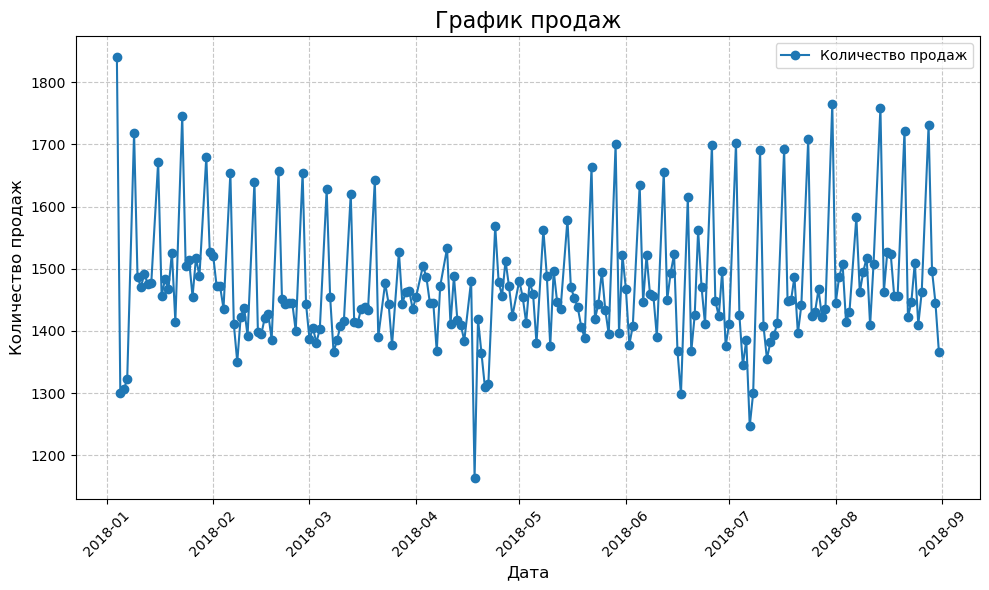

In [16]:
# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(grouped_df['Дата'], grouped_df['Количество_Продаж'], marker='o', linestyle='-', label='Количество продаж')

# Настройки графика
plt.title('График продаж', fontsize=16)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество продаж', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=10)
plt.xticks(rotation=45)
plt.tight_layout()

# Показ графика
plt.show()

In [ ]:
Опишите что вы видите на графике. Ваша задача - максимально описать график

In [ ]:
Название графика:

График показывает динамику количества продаж в зависимости от даты.
Оси:
Ось X (горизонтальная): На ней отображаются даты. Они представлены в формате год-месяц-день (например, 2023-01-01). 
Ось Y (вертикальная): Она показывает количество продаж. Значения на оси увеличиваются с шагом, соответствующим интервалу данных.

Данные:
График отображает продажи, соответствующие месяцам за 2018 год с января по сентябрь.
Для каждой даты имеется одна точка, соединённая линией с соседними, что делает график линейным.
Вид графика:

Тип графика: Линейный график с маркерами (o), которые выделяют конкретные значения данных.
Линии соединяют точки, что создаёт визуализацию тренда изменений в данных.
Тренд:

На 2018-01 продажи начинаются на уровне 1840.
На 2018-02 продажи падают до 1301.
Далее по месяцам мы видим то рост то спад, но к концу периода 2018-09 наблюдается рост продаж до 1719
    

Сетка:
График имеет сетку, которая помогает точнее интерпретировать значения, соотнеся их с осями.

Легенда:
График имеет легенду "Количество продаж", которая объясняет, что именно представлено на графике.

Выводы:
Резкий рост продаж наблюдается в начале на 2018-01
Снижение продаж происходит между 2018-04 и 2018-05.
График показывает, что данные изменчивы, и требуется дополнительный анализ для понимания причин колебаний.

In [ ]:
Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у df)

In [17]:
# Группировка по дате для подсчёта количества продаж
grouped_df = df.groupby('Дата').size().reset_index(name='Количество_Продаж')

# Рассчитаем IQR (межквартильный размах) для количества продаж
q1 = grouped_df['Количество_Продаж'].quantile(0.25)  # Первый квартиль
q3 = grouped_df['Количество_Продаж'].quantile(0.75)  # Третий квартиль
iqr = q3 - q1  # Межквартильный размах

# Границы для выбросов
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Фильтруем строки с выбросами
outliers = grouped_df[(grouped_df['Количество_Продаж'] < lower_bound) | (grouped_df['Количество_Продаж'] > upper_bound)]

# Найдём строку с максимальным выбросом
if not outliers.empty:
    max_outlier = outliers.loc[outliers['Количество_Продаж'].idxmax()]
    print("Строка с максимальным выбросом:")
    print(max_outlier)
else:
    print("Выбросов не найдено.")

Строка с максимальным выбросом:
Дата                 2018-01-04 00:00:00
Количество_Продаж                   1840
Name: 0, dtype: object


In [ ]:
Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [18]:
# Фильтруем по средам, июню, июлю и августу, и складу 3
filtered_df = df[
    (df['Дата'].dt.month.isin([6, 7, 8])) &  # Июнь, июль, август
    (df['Дата'].dt.weekday == 2) &  # Среда (в pandas понедельник = 0, среда = 2)
    (df['Склад'] == 3)  # Склад 3
]

# Группируем по номенклатуре и суммируем количество
grouped_df = filtered_df.groupby('Номенклатура')['Количество'].sum().reset_index()

# Находим товар с максимальными продажами
top_product = grouped_df.loc[grouped_df['Количество'].idxmax()]

# Вывод результата
print("Топовый товар по продажам:")
print(top_product)

Топовый товар по продажам:
Номенклатура    product_1
Количество           2267
Name: 1, dtype: object


In [ ]:
Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее 
преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с grouped_df,
и нарисуйте график y=['Количество продаж', 'T'], где Т это температура. А также отдельно график температуры

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Читаем CSV-файл с погодой, пропуская первые строки с ненужной информацией
weather = pd.read_csv('weather.csv', delimiter=';', encoding='utf-8', skiprows=6)
print(weather.head())

                  Местное время в Астане      T     Po    P  Pa  \
30.04.2018 23:00                     8.0  727.8  759.1  1.8  63   
30.04.2018 20:00                    13.4  726.0  756.7  0.6  45   
30.04.2018 17:00                    16.0  725.4  755.8  0.0  30   
30.04.2018 14:00                    16.5  725.4  755.7 -0.3  37   
30.04.2018 11:00                    10.9  725.7  756.6  0.5  68   

                                                     U  DD  Ff  ff10  \
30.04.2018 23:00         Ветер, дующий с северо-запада   2 NaN   NaN   
30.04.2018 20:00     Ветер, дующий с западо-юго-запада   2 NaN   NaN   
30.04.2018 17:00  Ветер, дующий с западо-северо-запада   3 NaN   NaN   
30.04.2018 14:00  Ветер, дующий с северо-северо-запада   3 NaN   NaN   
30.04.2018 11:00                Ветер, дующий с севера   1 NaN   NaN   

                                        ff3  ...  \
30.04.2018 23:00                    20–30%.  ...   
30.04.2018 20:00  90  или более, но не 100%  ...   
30.04.20

In [58]:
# 2. Оставляем только столбцы "Местное время в Астане" и "T" (Температура)
weather = weather[['Местное время в Астане', 'T']]
print(weather.head())

                  Местное время в Астане      T
30.04.2018 23:00                     8.0  727.8
30.04.2018 20:00                    13.4  726.0
30.04.2018 17:00                    16.0  725.4
30.04.2018 14:00                    16.5  725.4
30.04.2018 11:00                    10.9  725.7


In [59]:
# 3. Переименовываем колонки для удобства
weather.columns = ['Дата', 'Температура']
print(weather.head())

                  Дата  Температура
30.04.2018 23:00   8.0        727.8
30.04.2018 20:00  13.4        726.0
30.04.2018 17:00  16.0        725.4
30.04.2018 14:00  16.5        725.4
30.04.2018 11:00  10.9        725.7


In [60]:
# 4. Преобразуем дату в формат datetime
weather['Дата'] = pd.to_datetime(weather['Дата'], dayfirst=True)
print(weather.head())

                                          Дата  Температура
30.04.2018 23:00 1970-01-01 00:00:00.000000008        727.8
30.04.2018 20:00 1970-01-01 00:00:00.000000013        726.0
30.04.2018 17:00 1970-01-01 00:00:00.000000016        725.4
30.04.2018 14:00 1970-01-01 00:00:00.000000016        725.4
30.04.2018 11:00 1970-01-01 00:00:00.000000010        725.7


In [63]:
# 5. Группируем по дням, чтобы получить среднюю температуру за день
weather_daily = weather.groupby(weather['Дата'].dt.date).mean().reset_index()
print(weather.head())

ValueError: cannot insert Дата, already exists

In [64]:
# 6. Загружаем таблицу с продажами
grouped_df = pd.read_csv('sales.csv')  # Укажите правильный путь

FileNotFoundError: [Errno 2] No such file or directory: 'sales.csv'

In [56]:











# 7. Преобразуем дату в datetime
grouped_df['Дата'] = pd.to_datetime(grouped_df['Дата'], dayfirst=True)

# 8. Объединяем таблицы по дате
merged_df = pd.merge(grouped_df, weather_daily, on='Дата', how='inner')

# 9. Строим график: количество продаж и температура
plt.figure(figsize=(10, 5))
plt.plot(merged_df['Дата'], merged_df['Количество продаж'], label='Количество продаж', color='blue')
plt.plot(merged_df['Дата'], merged_df['Температура'], label='Температура', color='red')
plt.xlabel('Дата')
plt.ylabel('Значение')
plt.title('Количество продаж и температура')
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.show()

# 10. Строим отдельный график температуры
plt.figure(figsize=(10, 5))
plt.plot(merged_df['Дата'], merged_df['Температура'], color='red', label='Температура')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.title('Температура в Астане')
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.show()



ValueError: cannot insert Дата, already exists

In [49]:
df_weather = df_weather[['Местное время в Астане', 'T']].rename(columns={'Местное время в Астане': 'Дата', 'T': 'Температура'})


In [50]:
df_weather['Дата'] = pd.to_datetime(df_weather['Дата'], format='%d.%m.%Y %H:%M')


ValueError: time data "8" doesn't match format "%d.%m.%Y %H:%M", at position 0. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [ ]:
# Посмотрим на структуру данных
print(df_weather.head())

# Предположим, что нужные колонки называются "Дата" и "Средняя температура"
df_weather = df_weather[['Дата', 'Средняя температура']]
df_weather['Дата'] = pd.to_datetime(df_weather['Дата'], dayfirst=True)

# Преобразуем температуру в число (на случай, если есть текст)
df_weather['Средняя температура'] = df_weather['Средняя температура'].str.replace(',', '.').astype(float)